# 00 · Setup check

Before we touch any chess data, this notebook checks that every tool the project needs works on this computer. Run it top to bottom (**Run All**). Each section explains what it checks and what you should see.

**Kernel:** pick the project's `.venv` Python (in VS Code: *Select Kernel → .venv*). If you haven't set it up yet, follow the README.

## 1. Do the main libraries load?

These are the building blocks of the project:
- **torch** (PyTorch): does the actual math of training a model
- **transformers**: downloads and runs models like Gemma
- **trl** and **peft**: add the training methods we use (SFT, DPO, RL) and LoRA, the cheap way of fine-tuning
- **chess** (python-chess): understands chess rules: boards, legal moves, notation

If any of these fail to import, nothing else will work.

In [1]:
import chess
import chess.engine
import peft
import torch
import transformers
import trl

for library in [torch, transformers, trl, peft, chess]:
    print(f"{library.__name__:<13} {library.__version__}")

W1102 00:47:43.553000 27760 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


torch         2.15.0+cu132
transformers  5.22.1
trl           1.17.1
peft          0.21.2
chess         1.11.2


## 2. What hardware do we have?

Training a model needs a GPU (a graphics chip). This tells us what this computer offers:
- **CUDA**: an NVIDIA GPU. This is what full training needs.
- **MPS**: the Mac's built-in GPU. Fine for small tests, too slow and limited for real training.
- **CPU**: no GPU. Fine for data processing.

In [2]:
if torch.cuda.is_available():
    major, minor = torch.cuda.get_device_capability()
    print(f"CUDA GPU: {torch.cuda.get_device_name()} (compute capability {major}.{minor})")
elif torch.backends.mps.is_available():
    print("Apple MPS (Mac GPU): good for small tests, not for full training")
else:
    print("CPU only: good for data processing and tiny tests")

CUDA GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU (compute capability 12.0)


## 3. Does Stockfish work?

**Stockfish** is a free (and very strong chess engine, lol). We use it as our reference for how good a move is.

Its unit is the **centipawn**, one hundredth of a pawn: +100 means White is about one pawn ahead, and negative numbers mean Black is ahead. **Depth** is how many moves ahead it searches. We fix it (in `configs/eval.yaml`) so every score is computed the same way.

We ask it about two positions whose answers we already know, so we can tell whether its scores make sense:
1. **The normal starting position.** Both sides have the same pieces, but White moves first, which is worth a small advantage. We expect a score slightly above 0: a few tens of centipawns.
2. **The starting position with Black's queen removed** (the square d8 is empty). Nothing else changes, so the score should rise by about the value of a queen, roughly 900 centipawns (9 pawns).

You'll see below that the two checks confirm the **sign** (positive means good for White) and the **scale** (a queen is worth about 900). We are doing this just to see how Stockfish values different pieces and how things are scored.

In [3]:
from chesslm.config import load_config
from chesslm.engine import open_engine

stockfish_cfg = load_config("eval")["stockfish"]
engine = open_engine(stockfish_cfg["path"])
limit = chess.engine.Limit(depth=stockfish_cfg["depth"])


def describe(board):
    """Ask Stockfish for the score (White's point of view) and its best move."""
    info = engine.analyse(board, limit)
    score = info["score"].white().score()
    best = info["pv"][0]
    return f"{score:+d} centipawns for White, best move {best.uci()} ({board.san(best)})"


start = chess.Board()
no_black_queen = chess.Board("rnb1kbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQKBNR w KQkq - 0 1")

print("Starting position:      ", describe(start))
print("Black's queen removed:  ", describe(no_black_queen))
engine.quit()

Starting position:       +32 centipawns for White, best move e2e4 (e4)
Black's queen removed:   +886 centipawns for White, best move e2e4 (e4)


**Reading the output**
- **Starting position, +32:** about a third of a pawn for White, the usual small advantage of moving first.
- **Black's queen removed, +886:** 854 centipawns more than the starting position, close to the 900 a queen is worth. Stockfish values material the way chess players do.
- **Best move e2e4 (e4) in both:** the move is printed in both notations, UCI (from e2 to e4) and SAN. Advancing the king's pawn two squares is a standard strong first move. Removing Black's queen does not create anything White can capture right away, so the best move stays the same.
- The exact numbers can differ slightly with another Stockfish version or search depth. What matters is that they are close to these expectations.

This matters later, because, to grade a move, evaluation compares Stockfish's score after its own best move with the score after the model's move. The difference is the **centipawn loss**. For example, a move that gives away the queen for nothing loses about 900 centipawns, close to our cap of 1000 (`configs/eval.yaml`).

This is what a board looks like to the code: a **FEN**, a one-line text code for the whole position. Below is the queenless position, drawn from its FEN.

rnb1kbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQKBNR w KQkq - 0 1


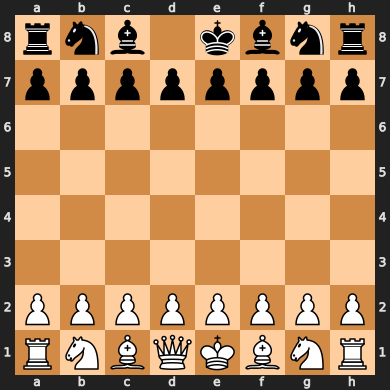

In [4]:
print(no_black_queen.fen())
no_black_queen

## 4. Can we load the model's tokenizer?

We know that a model reads **tokens**, chunks of text (often parts of words). The **tokenizer** converts text into tokens. Downloading only the tokenizer is quick (a few MB), so it's a cheap way to check that we can reach the model on Hugging Face before the big ~10 GB download in Step 4.

Gemma is a chat model, so every message is wrapped in a fixed **chat template** that marks who is speaking. This is exactly the format our chess prompts will use.

In [5]:
from transformers import AutoTokenizer

model_id = load_config("sft")["model"]["id"]
tokenizer = AutoTokenizer.from_pretrained(model_id)
print(f"Model: {model_id}")
print(f"Vocabulary: {len(tokenizer):,} different tokens\n")

messages = [{"role": "user", "content": "What is the best move? Answer with one move."}]
prompt = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
print("What the model actually sees:")
print(prompt)

config.json:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

D:\CS 289A\cs289-final-project\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\natha\.cache\huggingface\hub\models--google--gemma-4-E2B-it. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/3.08k [00:00<?, ?B/s]

D:\CS 289A\cs289-final-project\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\natha\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer.json: reconstructing file:   0%|          |  0.00B / 32.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/18.6k [00:00<?, ?B/s]

Model: google/gemma-4-E2B-it
Vocabulary: 262,144 different tokens

What the model actually sees:
<bos><|turn>user
What is the best move? Answer with one move.<turn|>
<|turn>model



### How does the model see chess moves?

This matters for a decision coming up in Step 2: should moves be written in **UCI** (`e2e4`, from-square + to-square) or **SAN** (`e4`, `Nf3`, the notation people use)? Here's how the tokenizer splits each, and how it splits a FEN. Fewer, cleaner pieces can make a move easier for the model to learn.

In [6]:
examples = {
    "UCI  e2e4": "e2e4",
    "UCI  g1f3": "g1f3",
    "SAN  e4": "e4",
    "SAN  Nf3": "Nf3",
    "SAN  O-O (castling)": "O-O",
    "FEN (starting position)": chess.STARTING_FEN,
}
for label, text in examples.items():
    pieces = tokenizer.tokenize(text)
    print(f"{label:<26} {len(pieces):>2} tokens: {pieces}")

UCI  e2e4                   4 tokens: ['e', '2', 'e', '4']
UCI  g1f3                   4 tokens: ['g', '1', 'f', '3']
SAN  e4                     2 tokens: ['e', '4']
SAN  Nf3                    3 tokens: ['N', 'f', '3']
SAN  O-O (castling)         3 tokens: ['O', '-', 'O']
FEN (starting position)    30 tokens: ['r', 'nb', 'qk', 'bnr', '/', 'pppp', 'pppp', '/', '8', '/', '8', '/', '8', '/', '8', '/', 'PPPP', 'PPPP', '/', 'RNB', 'QK', 'BN', 'R', '▁w', '▁KQkq', '▁-', '▁', '0', '▁', '1']


## Summary

If every cell above ran without errors, the setup is complete.
- the libraries load
- we know which hardware we have
- Stockfish scores positions sensibly
- the Gemma 4 tokenizer loads

`01_data_pipeline.ipynb` turns Lichess games into training examples and Lichess puzzles into the test set.